# A abstenção decidiu o segundo turno de 2026?

No primeiro turno, a pergunta era se a abstenção explicava a vantagem de Flávio Bolsonaro (notebook `primeiro-turno/analise_abstencao_2026.ipynb`; resposta: não). No segundo turno a abstenção fez algo raro: **caiu**. Quase 3 milhões de pessoas a mais foram votar em 25/10 do que em 4/10, e Lula venceu por 4,4 milhões.

Então a pergunta se inverte: **foi a volta desses eleitores que deu a vitória a Lula?**

O caminho:

1. conferir os números com o TSE;
2. colocar a queda na série histórica do segundo turno;
3. ver onde ela aconteceu (estado, tamanho de município);
4. testar se ela foi maior onde Lula era mais forte;
5. medir o quanto ela poderia, no máximo, ter mudado o resultado;
6. comparar com o segundo turno de 2022;
7. ver que tipo de município puxou a queda.

**Dados:** presidente por município, 1º e 2º turno de 2026 (portal de resultados do TSE, `src/download_tse.py`) e de 2022 (CDN do TSE, `src/prepare_segundo_turno.py`); série nacional 2002–2018 em `serie_historica.csv`; perfil municipal do Censo 2022 (IBGE SIDRA, mesmo script).

**Ressalva:** a unidade é o município. "A abstenção caiu mais em cidades lulistas" não quer dizer que os eleitores que voltaram votaram em Lula.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

DATA = Path("../data/processed")
pd.options.display.float_format = "{:,.2f}".format

LULA, FLAVIO, CINZA, TINTA = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10, "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})
pct = lambda x, y: 100 * x / y

REGIAO = {
    **dict.fromkeys("AC AP AM PA RO RR TO".split(), "Norte"),
    **dict.fromkeys("AL BA CE MA PB PE PI RN SE".split(), "Nordeste"),
    **dict.fromkeys("DF GO MT MS".split(), "Centro-Oeste"),
    **dict.fromkeys("ES MG RJ SP".split(), "Sudeste"),
    **dict.fromkeys("PR RS SC".split(), "Sul"),
}

r26 = pd.read_csv(DATA / "presidente_municipio_2026.csv")
r22 = pd.read_csv(DATA / "presidente_municipio_2022.csv")
ib = pd.read_csv(DATA / "ibge_municipio_2022.csv")

## 1. Conferindo com o TSE

Totais nacionais (com exterior) de cada turno. Os votos de Lula e do PL batem com o resultado oficial; o `assert` falha se não baterem.

In [2]:
def nacional(d):
    g = d.groupby("turno")[["aptos", "comparecimento", "abstencao", "brancos", "nulos", "validos", "c13", "c22"]].sum()
    g["abstenção %"] = pct(g.abstencao, g.aptos)
    g["Lula % válidos"] = pct(g.c13, g.validos)
    return g

n22, n26 = nacional(r22), nacional(r26)
assert tuple(n26.c13) == (53_879_538, 64_256_232) and tuple(n26.c22) == (56_104_503, 59_826_041)
assert tuple(n22.c13) == (57_259_504, 60_345_999) and n22.c22[2] == 58_206_354
display(pd.concat({2022: n22, 2026: n26}).style.format("{:,.0f}").format("{:.2f}", subset=["abstenção %", "Lula % válidos"]))

d_abst = n26.abstencao[1] - n26.abstencao[2]
margem = n26.c13[2] - n26.c22[2]
print(f"2026: abstenção {n26['abstenção %'][1]:.2f}% → {n26['abstenção %'][2]:.2f}% "
      f"({n26['abstenção %'][2] - n26['abstenção %'][1]:+.2f} p.p., {d_abst:,.0f} pessoas a menos)")
print(f"margem de Lula no 2º turno: {margem:,.0f}")

2026: abstenção 21.08% → 19.22% (-1.86 p.p., 2,960,239 pessoas a menos)
margem de Lula no 2º turno: 4,430,191


## 2. Uma queda sem precedente na série

De 2002 a 2018, a abstenção sempre **subiu** do primeiro para o segundo turno, entre 1 e 3,4 p.p. O padrão é intuitivo: com menos cargos em jogo e, em muitos lugares, sem disputa local, menos gente sai de casa. Em 2022 ela caiu pela primeira vez (−0,4 p.p.). Em 2026 caiu quase cinco vezes mais.

,1º turno,2º turno,Δ 1º→2º
ano,,,
2002,17.74,20.47,2.73
2006,16.75,18.99,2.24
2010,18.12,21.50,3.37
2014,19.40,21.10,1.71
2018,20.33,21.30,0.97
2022,20.95,20.58,-0.36
2026,21.08,19.22,-1.86


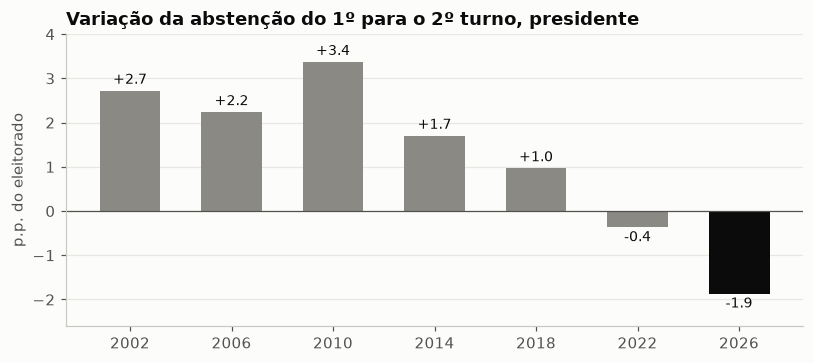

In [3]:
h = pd.read_csv(DATA / "serie_historica.csv")
h = h.assign(abst_pct=pct(h.abst, h.aptos)).pivot(index="ano", columns="turno", values="abst_pct")
for ano, n in ((2022, n22), (2026, n26)):
    h.loc[ano] = n["abstenção %"].values
h["Δ 1º→2º"] = h[2] - h[1]
h.columns = ["1º turno", "2º turno", "Δ 1º→2º"]
display(h)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
cores = [TINTA if a == 2026 else CINZA for a in h.index]
b = ax.bar(h.index.astype(str), h["Δ 1º→2º"], color=cores, width=0.6)
for r, v in zip(b, h["Δ 1º→2º"]):
    ax.text(r.get_x() + r.get_width() / 2, v + (0.08 if v > 0 else -0.08), f"{v:+.1f}",
            ha="center", va="bottom" if v > 0 else "top", fontsize=9)
ax.axhline(0, color="#52514e", lw=0.8); ax.grid(axis="x", visible=False)
ax.set_ylim(-2.6, 4); ax.set_ylabel("p.p. do eleitorado")
ax.set_title("Variação da abstenção do 1º para o 2º turno, presidente")
plt.tight_layout(); plt.show()

## 3. Onde ela caiu

Painel de municípios presentes nas quatro eleições (2022 e 2026, dois turnos), sem o exterior.

5,570 municípios no painel; a abstenção caiu entre os turnos em 80% deles


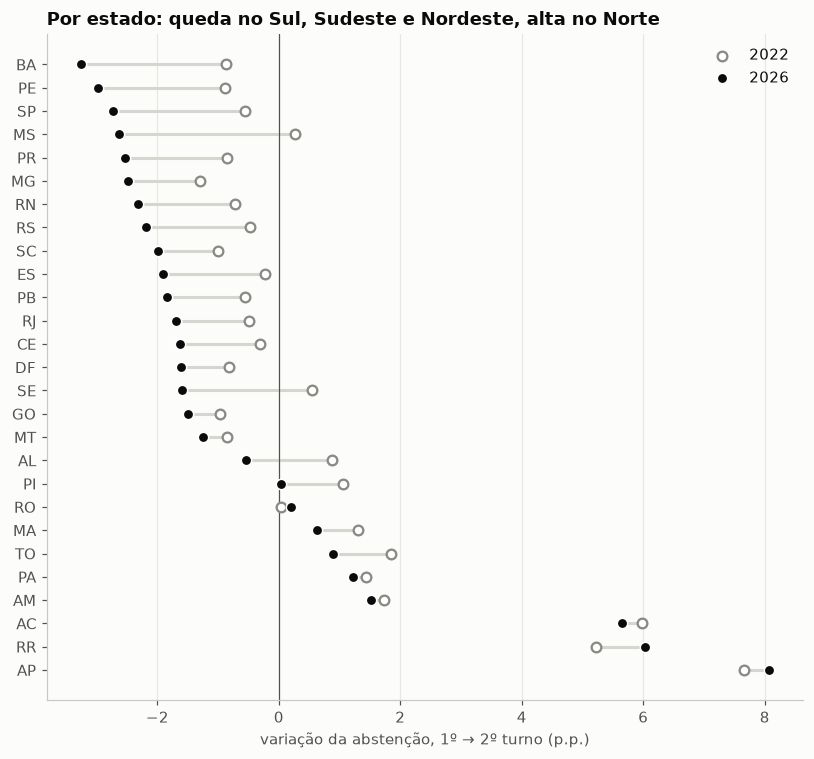

UFs com queda em 2026: 18 de 27 | em 2022: 15


In [4]:
def turno(d, t, s):
    x = d[d.turno == t].set_index("cd_tse")
    return pd.DataFrame({f"aptos{s}": x.aptos, f"abst{s}": x.abstencao, f"lula{s}": x.c13,
                         f"dir{s}": x.c22, f"val{s}": x.validos, f"bn{s}": x.brancos + x.nulos})

base = r26[r26.turno == 1].set_index("cd_tse")[["uf", "municipio", "cd_ibge"]]
m = (base.join(turno(r26, 1, "_1t26")).join(turno(r26, 2, "_2t26"))
     .join(turno(r22, 1, "_1t22"), how="inner").join(turno(r22, 2, "_2t22"), how="inner"))
m = m[m.uf != "ZZ"].copy()
m["regiao"] = m.uf.map(REGIAO)
for s in ("_1t22", "_2t22", "_1t26", "_2t26"):
    m["ab" + s] = pct(m["abst" + s], m["aptos" + s])
    m["lh" + s] = pct(m["lula" + s], m["lula" + s] + m["dir" + s])   # Lula no confronto direto
m["lula_val_1t26"] = pct(m.lula_1t26, m.val_1t26)
m["d_rodada"] = m.ab_2t26 - m.ab_1t26        # 1º→2º turno de 2026
m["d_rodada22"] = m.ab_2t22 - m.ab_1t22      # 1º→2º turno de 2022
m["d_ano"] = m.ab_2t26 - m.ab_2t22           # 2º turno 2022→2026
m["peso"] = m.aptos_2t26
print(f"{len(m):,} municípios no painel; a abstenção caiu entre os turnos em {(m.d_rodada < 0).mean():.0%} deles")

def agrega(g):
    taxa = lambda s: pct(g["abst" + s].sum(), g["aptos" + s].sum())
    return pd.Series({"municípios": len(g), "eleitores 2º t (mi)": g.aptos_2t26.sum() / 1e6,
                      "abst 1º t 2026": taxa("_1t26"), "abst 2º t 2026": taxa("_2t26"),
                      "Δ 2026": taxa("_2t26") - taxa("_1t26"), "Δ 2022": taxa("_2t22") - taxa("_1t22")})

uf = m.groupby("uf").apply(agrega).sort_values("Δ 2026")
fig, ax = plt.subplots(figsize=(7.5, 7))
y = np.arange(len(uf))[::-1]
ax.scatter(uf["Δ 2022"], y, s=40, color="white", edgecolor=CINZA, lw=1.5, zorder=3, label="2022")
ax.scatter(uf["Δ 2026"], y, s=46, color=TINTA, edgecolor="white", lw=1, zorder=4, label="2026")
for yi, (a, b) in zip(y, uf[["Δ 2022", "Δ 2026"]].values):
    ax.plot([a, b], [yi, yi], color="#d6d5cf", lw=2, zorder=2)
ax.set_yticks(y, uf.index); ax.axvline(0, color="#52514e", lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("variação da abstenção, 1º → 2º turno (p.p.)")
ax.set_title("Por estado: queda no Sul, Sudeste e Nordeste, alta no Norte"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
print(f"UFs com queda em 2026: {(uf['Δ 2026'] < 0).sum()} de {len(uf)} | em 2022: {(uf['Δ 2022'] < 0).sum()}")

,municípios,eleitores 2º t (mi),abst 1º t 2026,abst 2º t 2026,Δ 2026,Δ 2022
porte,,,,,,
até 10 mil,"2,940.00",15.75,20.67,19.51,-1.16,0.02
10–50 mil,"2,134.00",44.06,21.09,19.60,-1.49,-0.16
50–200 mil,394.00,35.88,20.58,18.66,-1.92,-0.54
200 mil–1 mi,90.00,32.81,20.24,18.31,-1.94,-0.32
mais de 1 mi,12.00,29.33,21.55,18.97,-2.58,-0.68


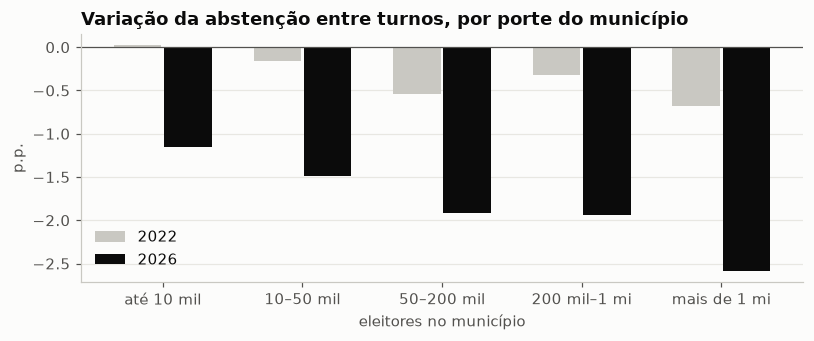

In [5]:
m["porte"] = pd.cut(m.aptos_2t26, [0, 10e3, 50e3, 200e3, 1e6, 1e8],
                    labels=["até 10 mil", "10–50 mil", "50–200 mil", "200 mil–1 mi", "mais de 1 mi"])
porte = m.groupby("porte").apply(agrega)
display(porte)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
x = np.arange(len(porte))
ax.bar(x - 0.18, porte["Δ 2022"], width=0.34, color="#c9c8c2", label="2022")
ax.bar(x + 0.18, porte["Δ 2026"], width=0.34, color=TINTA, label="2026")
ax.set_xticks(x, porte.index); ax.axhline(0, color="#52514e", lw=0.8); ax.grid(axis="x", visible=False)
ax.set_ylabel("p.p."); ax.set_xlabel("eleitores no município")
ax.set_title("Variação da abstenção entre turnos, por porte do município"); ax.legend()
plt.tight_layout(); plt.show()

**Leitura.** A queda de 2026 se concentrou em 18 estados do Sul, Sudeste, Centro-Oeste e Nordeste, com as maiores na BA (−3,3 p.p.), em PE e SP. No Norte foi o contrário: a abstenção **subiu** em todos os sete estados da região (e também no MA e no PI), com altas fortes no AP (+8,1), RR (+6,0) e AC (+5,7), o padrão clássico de segundo turno. Uma explicação candidata é a existência (ou não) de segundo turno para governador em cada estado, que não verifiquei aqui.

Por porte, a queda cresce com o tamanho da cidade: pouco mais de 1 p.p. nos municípios com até 10 mil eleitores, 2,6 p.p. nas capitais com mais de 1 milhão. Em 2022 o gradiente tinha o mesmo formato, só que bem mais fraco. Os dados não dizem por quê. Transporte público gratuito no dia da eleição e o horário de votação são hipóteses que pesam mais nas cidades grandes, mas não são testadas aqui (o horário tem notebook próprio, `analise_horario_votacao.ipynb`).

## 4. Teste central: a abstenção caiu mais onde Lula era mais forte?

Se a volta dos eleitores tivesse beneficiado Lula, seria de esperar uma queda maior nos municípios lulistas. Divido os municípios em decis da votação de Lula no primeiro turno (% dos válidos, cada decil com ~10% dos municípios) e meço a variação da abstenção entre os turnos.

,municípios,abst 1º t 2026,abst 2º t 2026,Δ 2026,Δ 2022
decil,,,,,
1,557.00,19.85,18.32,-1.53,-0.89
2,557.00,21.10,19.13,-1.97,-0.82
3,557.00,21.67,19.81,-1.86,-0.51
4,557.00,21.20,19.53,-1.66,-0.43
5,557.00,22.52,20.39,-2.13,-0.49
6,557.00,21.90,19.63,-2.27,-0.27
7,557.00,18.08,16.47,-1.61,-0.05
8,557.00,19.57,17.60,-1.96,-0.23
9,557.00,19.64,18.41,-1.24,0.35


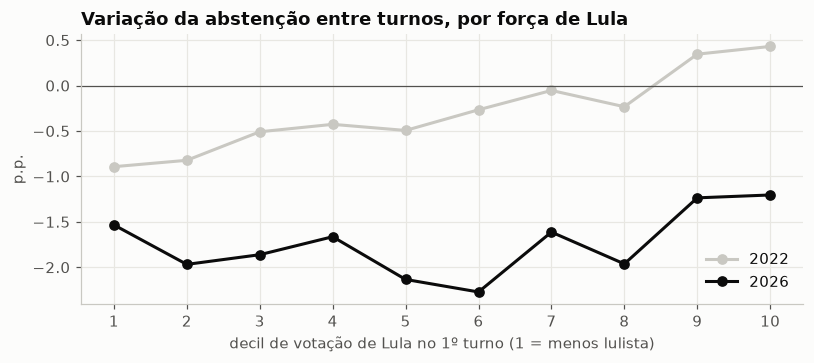

In [6]:
m["decil"] = pd.qcut(m.lula_val_1t26, 10, labels=range(1, 11))
dec = m.groupby("decil").apply(agrega)[["municípios", "abst 1º t 2026", "abst 2º t 2026", "Δ 2026", "Δ 2022"]]
display(dec)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(dec.index.astype(int), dec["Δ 2022"], marker="o", color="#c9c8c2", lw=2, label="2022")
ax.plot(dec.index.astype(int), dec["Δ 2026"], marker="o", color=TINTA, lw=2, label="2026")
ax.axhline(0, color="#52514e", lw=0.8); ax.set_xticks(range(1, 11))
ax.set_xlabel("decil de votação de Lula no 1º turno (1 = menos lulista)"); ax.set_ylabel("p.p.")
ax.set_title("Variação da abstenção entre turnos, por força de Lula"); ax.legend()
plt.tight_layout(); plt.show()

In [7]:
def fit(f, d=m):
    return smf.wls(f, data=d, weights=d.peso).fit(cov_type="cluster", cov_kwds={"groups": d.uf})

mods = {
    "(1) sem controles": "d_rodada ~ lula_val_1t26",
    "(2) mesmo estado (efeito fixo de UF)": "d_rodada ~ lula_val_1t26 + C(uf)",
}
tab = pd.DataFrame({k: {"coef. (p.p. por +10 p.p. de Lula)": 10 * (r := fit(f)).params["lula_val_1t26"],
                        "p-valor": r.pvalues["lula_val_1t26"], "R²": r.rsquared} for k, f in mods.items()}).T
display(tab)

# o ganho de Lula entre os turnos foi maior onde mais gente voltou?
r = fit("I(lh_2t26 - lh_1t26) ~ d_rodada + C(uf)")
print(f"ganho de Lula no confronto direto (p.p.) por −1 p.p. de abstenção, dentro da UF: "
      f"{-r.params['d_rodada']:+.3f} (p = {r.pvalues['d_rodada']:.2f})")

,coef. (p.p. por +10 p.p. de Lula),p-valor,R²
(1) sem controles,0.07,0.66,0.00
(2) mesmo estado (efeito fixo de UF),0.08,0.53,0.61


ganho de Lula no confronto direto (p.p.) por −1 p.p. de abstenção, dentro da UF: +0.061 (p = 0.30)


**Leitura.** Não há relação. A queda é de 1,2 a 2,3 p.p. em todos os decis, sem tendência, e o coeficiente é praticamente zero com ou sem efeito fixo de estado. Comparando municípios do mesmo estado, o ganho de Lula entre os turnos também não foi maior onde a abstenção caiu mais. Em 2022 havia um padrão fraco (a abstenção subia um pouco nos municípios lulistas e caía nos bolsonaristas); em 2026 nem isso.

## 5. Quanto a queda poderia, no máximo, ter mudado o resultado?

Dois exercícios, ambos deliberadamente generosos com a hipótese "foi a abstenção":

* **Teto absoluto.** Suponha que **todos** os 2,96 milhões de eleitores a mais votaram em Lula. Tirando-os, Lula ainda venceria?
* **Contrafactual proporcional.** Mantenho o comparecimento de cada município no nível do primeiro turno e aplico as fatias observadas no segundo turno. É a hipótese de que quem voltou votou como o resto da cidade.

In [8]:
print(f"Teto absoluto: margem {margem:,.0f} − {d_abst:,.0f} eleitores a mais = {margem - d_abst:,.0f} "
      f"(Lula ainda à frente)")

def contrafactual(ab_ref):
    f = (1 - ab_ref / 100) / (1 - m.ab_2t26 / 100)
    L, F = (m.lula_2t26 * f).sum(), (m.dir_2t26 * f).sum()
    return pd.Series({"Lula %": pct(L, L + F), "margem": L - F})

obs = pd.Series({"Lula %": pct(m.lula_2t26.sum(), (m.lula_2t26 + m.dir_2t26).sum()),
                 "margem": (m.lula_2t26 - m.dir_2t26).sum()})
cf = pd.DataFrame({"observado (sem exterior)": obs,
                   "comparecimento do 1º turno de 2026": contrafactual(m.ab_1t26),
                   "comparecimento do 2º turno de 2022": contrafactual(m.ab_2t22)}).T
display(cf.style.format({"Lula %": "{:.2f}", "margem": "{:,.0f}"}))

Teto absoluto: margem 4,430,191 − 2,960,239 eleitores a mais = 1,469,952 (Lula ainda à frente)


,Lula %,margem
observado (sem exterior),51.78,"4,402,942"
comparecimento do 1º turno de 2026,51.79,"4,333,357"
comparecimento do 2º turno de 2022,51.65,"4,007,074"


**Leitura.** Mesmo no caso extremo, em que cada eleitor que voltou votou em Lula, ele venceria por 1,5 milhão. No contrafactual proporcional, a margem quase não se mexe (4,33 contra 4,40 milhões): como a queda foi homogênea entre municípios lulistas e bolsonaristas, ela não desloca o resultado.

Com dados municipais, a única brecha é dentro de cada cidade: se, *no mesmo município*, quem voltou fosse muito mais lulista que o resto. Isso os agregados não descartam. O modelo de fluxos do notebook `eleicao-inteira/analise_virada_segundo_turno.ipynb` estima que a queda da abstenção rendeu cerca de **0,6 milhão** de margem a Lula, uns 9% da virada de 6,7 milhões. É uma estimativa ecológica, com as ressalvas que estão lá.

## 6. Comparando com o segundo turno de 2022

A mesma eleição de quatro anos antes, Lula × Bolsonaro. A abstenção do segundo turno caiu de 20,58% para 19,22%, mas o eleitorado também cresceu.

In [9]:
cols = {"Eleitores aptos": "aptos", "Lula": "c13", "PL (Bolsonaro → Flávio)": "c22",
        "Brancos + nulos": None, "Abstenções": "abstencao"}
def linha(n):
    return [n.aptos[2], n.c13[2], n.c22[2], n.brancos[2] + n.nulos[2], n.abstencao[2]]
acc = pd.DataFrame({"2º turno 2022": linha(n22), "2º turno 2026": linha(n26)}, index=list(cols))
acc["Δ"] = acc.iloc[:, 1] - acc.iloc[:, 0]
acc["Δ em p.p. do eleitorado"] = pct(acc.iloc[:, 1], n26.aptos[2]) - pct(acc.iloc[:, 0], n22.aptos[2])
acc.loc["Eleitores aptos", "Δ em p.p. do eleitorado"] = np.nan
display(acc.style.format({"2º turno 2022": "{:,.0f}", "2º turno 2026": "{:,.0f}", "Δ": "{:+,.0f}",
                          "Δ em p.p. do eleitorado": "{:+.2f}"}, na_rep="—"))

for k, f in {"sem controles": "d_ano ~ lh_2t22", "mesmo estado": "d_ano ~ lh_2t22 + C(uf)"}.items():
    r = fit(f)
    print(f"Δ abstenção 2º t 2022→2026 por +10 p.p. de Lula em 2022, {k}: {10 * r.params['lh_2t22']:+.2f} p.p. "
          f"(p = {r.pvalues['lh_2t22']:.2f})")

,2º turno 2022,2º turno 2026,Δ,Δ em p.p. do eleitorado
Eleitores aptos,"156,454,011","158,745,502","+2,291,491",—
Lula,"60,345,999","64,256,232","+3,910,233",+1.91
PL (Bolsonaro → Flávio),"58,206,354","59,826,041","+1,619,687",+0.48
Brancos + nulos,"5,700,443","4,153,801","-1,546,642",-1.03
Abstenções,"32,200,558","30,509,005","-1,691,553",-1.36


Δ abstenção 2º t 2022→2026 por +10 p.p. de Lula em 2022, sem controles: -0.49 p.p. (p = 0.00)
Δ abstenção 2º t 2022→2026 por +10 p.p. de Lula em 2022, mesmo estado: -0.23 p.p. (p = 0.34)


**Leitura.** De um segundo turno para o outro, Lula ganhou 3,9 milhões de votos e o PL, 1,6 milhão. A abstenção caiu 1,7 milhão de pessoas, mesmo com 2,3 milhões de eleitores a mais. Aqui aparece um padrão que não existe entre os turnos de 2026: a abstenção caiu mais nos municípios que deram mais votos a Lula em 2022. Mas é um padrão de estado. Comparando municípios do mesmo estado, o coeficiente encolhe para menos da metade e deixa de ser significativo. É o Nordeste votando mais em 2026 do que em 2022, não um efeito que se veja dentro de cada estado.

## 7. Que tipo de município puxou a queda?

Regressão da variação da abstenção entre os turnos de 2026 sobre o perfil do Censo 2022, com efeito fixo de UF, ponderada pelo eleitorado e com erros agrupados por estado. As variáveis estão padronizadas: o coeficiente é a variação em p.p. para +1 desvio-padrão. Negativo = a abstenção caiu **mais**.

5,570 municípios | R² = 0.67 (só UF: 0.60)


,coef. (p.p. por +1 DP),IC 95% inf,IC 95% sup,p-valor
renda (log),-0.30,-0.57,-0.02,0.03
população (log),-0.14,-0.34,0.06,0.17
% urbano,-0.47,-0.78,-0.16,0.00
% evangélicos,0.24,0.07,0.42,0.01
% pretos e pardos,0.05,-0.24,0.34,0.74
% sem fundamental completo,-0.30,-0.65,0.04,0.08


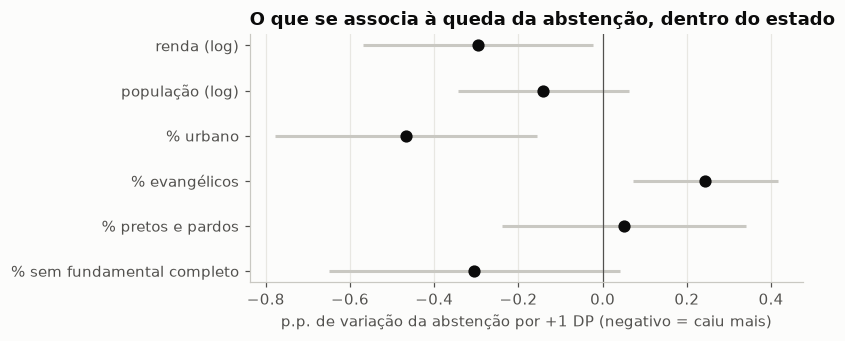

In [10]:
x = m.reset_index().merge(ib, on="cd_ibge", how="inner")
x["lrenda"], x["lpop"] = np.log(x.renda), np.log(x["pop"])
VARS = {"lrenda": "renda (log)", "lpop": "população (log)", "pct_urbano": "% urbano",
        "pct_evang": "% evangélicos", "pct_preta_parda": "% pretos e pardos",
        "pct_inst_baixa": "% sem fundamental completo"}
for c in VARS:
    x["z_" + c] = (x[c] - x[c].mean()) / x[c].std()
r = fit("d_rodada ~ " + " + ".join("z_" + c for c in VARS) + " + C(uf)", x)
z = [f"z_{c}" for c in VARS]
coef = pd.DataFrame({"coef. (p.p. por +1 DP)": r.params[z], "IC 95% inf": r.conf_int().loc[z, 0],
                     "IC 95% sup": r.conf_int().loc[z, 1], "p-valor": r.pvalues[z]})
coef.index = list(VARS.values())
print(f"{len(x):,} municípios | R² = {r.rsquared:.2f} (só UF: {fit('d_rodada ~ C(uf)', x).rsquared:.2f})")
display(coef)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
yy = np.arange(len(coef))[::-1]
ax.errorbar(coef.iloc[:, 0], yy, xerr=[coef.iloc[:, 0] - coef["IC 95% inf"], coef["IC 95% sup"] - coef.iloc[:, 0]],
            fmt="o", color=TINTA, ecolor="#c9c8c2", elinewidth=2, capsize=0, ms=7)
ax.set_yticks(yy, coef.index); ax.axvline(0, color="#52514e", lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("p.p. de variação da abstenção por +1 DP (negativo = caiu mais)")
ax.set_title("O que se associa à queda da abstenção, dentro do estado")
plt.tight_layout(); plt.show()

**Leitura.** O estado sozinho explica boa parte da variação. Dentro de cada estado, a abstenção caiu mais nos municípios **mais urbanos** e de **renda mais alta**, e menos nos mais evangélicos. Cor/raça não pesa. As variáveis andam juntas (renda, urbanização e instrução), então separar o efeito de cada uma é frágil (instrução baixa, por exemplo, sai com o mesmo sinal da renda alta, no limite da significância). O que fica é o retrato: a queda foi um fenômeno de cidade mais urbana e menos evangélica, não de um eleitorado específico de Lula ou de Flávio.

## 8. O que este notebook não cobre

* **Quem voltou a votar.** O TSE publica comparecimento por idade e escolaridade (`perfil_comparecimento_abstencao`), mas o arquivo de 2026 ainda não saiu. Com ele dá para ver se a queda veio de jovens, idosos ou de algum grupo de escolaridade.
* **Por que a abstenção caiu.** Transporte gratuito, mobilização das campanhas, a disputa mais apertada e o horário de votação são hipóteses plausíveis. Nenhuma é testada aqui.
* **Seção eleitoral.** O boletim de urna por seção do 2º turno ainda não foi publicado; quando sair, o mesmo teste dá para fazer dentro de cada cidade, que é a brecha que os dados municipais deixam (seção 5).

## 9. Conclusões

1. **A abstenção caiu de 21,08% para 19,22% entre os turnos**, 2,96 milhões de pessoas a menos. De 2002 a 2018 ela sempre subiu no segundo turno; 2026 tem a maior queda da série.
2. **A queda foi ampla, mas não uniforme.** Aconteceu em 18 estados e em 80% dos municípios, cresceu com o tamanho da cidade (de pouco mais de 1 p.p. nos menores a 2,6 p.p. nos com mais de 1 milhão de eleitores) e se inverteu no Norte, onde a abstenção subiu.
3. **Ela não foi maior onde Lula era forte.** A variação é a mesma em todos os decis de votação de Lula, e o ganho de Lula entre os turnos não acompanha a queda da abstenção dentro de cada estado.
4. **Ela não decidiu a eleição.** Mesmo que todos os eleitores que voltaram tivessem votado em Lula, ele ainda venceria por 1,5 milhão. Com a hipótese de que votaram como o resto da sua cidade, a margem quase não muda.
5. **A virada veio de outro lugar.** O notebook da virada estima que a queda da abstenção rendeu cerca de 0,6 milhão de margem; o grosso veio dos eleitores dos candidatos eliminados e de quem deixou de votar branco ou nulo.

**Limites.** Tudo é medido no município. Os dados descartam que a queda tenha favorecido Lula *entre* cidades, mas não *dentro* delas.